<div style="background: linear-gradient(135deg, #0a0e1a 0%, #0f1729 50%, #1a0a2e 100%); padding: 60px 40px; border-radius: 16px; border: 1px solid #1e3a5f; text-align: center; margin-bottom: 10px;">

<h1 style="font-size: 3.2em; font-weight: 900; background: linear-gradient(90deg, #7eb8f7, #a78bfa, #67e8c0); -webkit-background-clip: text; -webkit-text-fill-color: transparent; margin: 0 0 10px 0; letter-spacing: -1px;">
The Art of Chaos
</h1>

<p style="font-size: 0.9em; color: #3a5f8a; letter-spacing: 5px; text-transform: uppercase; margin: 0 0 20px 0; font-family: monospace;">
Part 2 &middot; Fractals and Chaos
</p>

<p style="font-size: 1.1em; color: #7a95b8; max-width: 700px; margin: 0 auto 30px auto; line-height: 1.8;">
Somewhere between order and randomness lives a universe of infinite complexity —
generated by equations so simple, a child could write them.
</p>

<div style="display: flex; justify-content: center; gap: 12px; flex-wrap: wrap;">
<span style="background: #0d1f35; border: 1px solid #1e3a5f; color: #7eb8f7; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">LORENZ</span>
<span style="background: #1a0d35; border: 1px solid #3a1f6a; color: #a78bfa; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">MANDELBROT</span>
<span style="background: #0d2a25; border: 1px solid #1a4a3a; color: #67e8c0; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">JULIA SETS</span>
<span style="background: #2a1f0d; border: 1px solid #4a3a1a; color: #f7c873; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">BIFURCATION</span>
<span style="background: #2a0d1f; border: 1px solid #4a1a35; color: #f472b6; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">LYAPUNOV</span>
</div>

</div>

## Contents

| # | Section | Topic |
|:---:|:---|:---|
| 05 | Julia Set Gallery | Eight constants, eight fractals |
| 06 | Lyapunov Exponents | Measuring how fast nearby paths separate |
| 07 | Animated Lorenz Attractor | A 200 frame rotating view |
| 08 | Poincare Sections | Slicing an orbit to reveal its structure |

Part 1 covers sections 1 to 4: the Lorenz attractor, the strange attractor gallery, bifurcation, and the Mandelbrot set.

[Back to Part 1](the-art-of-chaos-part1.ipynb)


---
## ⚙️ Setup & Configuration

In [1]:
# ╔══════════════════════════════════════════════════════════╗
# ║           IMPORTS & GLOBAL AESTHETIC CONFIG              ║
# ╚══════════════════════════════════════════════════════════╝

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.animation import FuncAnimation, PillowWriter
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import solve_ivp
import warnings
warnings.filterwarnings('ignore')

# ── Aesthetic dark palette ──────────────────────────────────
PALETTE = {
    'bg':      '#080b14',
    'surface': '#0d1117',
    'border':  '#1e2d45',
    'text':    '#8fa3c0',
    'blue':    '#7eb8f7',
    'purple':  '#a78bfa',
    'cyan':    '#67e8c0',
    'gold':    '#f7c873',
    'rose':    '#f472b6',
    'dim':     '#2a3f5f',
}

CMAPS = {
    'chaos':  LinearSegmentedColormap.from_list('chaos',
        ['#080b14','#0f2040','#1a0533','#4c1d95','#7eb8f7','#67e8c0','#f7c873'], N=512),
    'lorenz': LinearSegmentedColormap.from_list('lorenz',
        ['#080b14','#0c2461','#1e3799','#4a69bd','#7eb8f7','#a8d8f0','#ffffff'], N=512),
    'mandel': LinearSegmentedColormap.from_list('mandel',
        ['#080b14','#1a0533','#4c1d95','#a78bfa','#f7c873','#f472b6','#ffffff'], N=1024),
    'fire':   LinearSegmentedColormap.from_list('fire',
        ['#080b14','#3d0000','#c0392b','#e74c3c','#f39c12','#f7c873','#ffffff'], N=512),
    'bifur':  LinearSegmentedColormap.from_list('bifur',
        ['#080b14','#0d2137','#67e8c0','#a78bfa'], N=256),
}

plt.rcParams.update({
    'figure.facecolor':  PALETTE['bg'],
    'axes.facecolor':    PALETTE['surface'],
    'axes.edgecolor':    PALETTE['border'],
    'axes.labelcolor':   PALETTE['text'],
    'xtick.color':       PALETTE['dim'],
    'ytick.color':       PALETTE['dim'],
    'text.color':        PALETTE['text'],
    'grid.color':        PALETTE['border'],
    'grid.alpha':        0.4,
    'font.family':       'monospace',
    'figure.dpi':        130,
    'savefig.facecolor': PALETTE['bg'],
    'savefig.bbox':      'tight',
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

print("\u2746  Environment ready. Let the chaos begin.")

❆  Environment ready. Let the chaos begin.


In [ ]:
# Lorenz system, shared by the animation and the Poincare section
def lorenz(t, state, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = state
    return [sigma*(y - x), x*(rho - z) - y, x*y - beta*z]


---

<div style="background: linear-gradient(90deg, #2a0d1f, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #f472b6; margin: 20px 0;">
<p style="color: #6a1a40; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 05 · JULIA SETS — A FAMILY OF FRACTALS</p>
<h2 style="color: #f472b6; margin: 0; font-size: 1.8em;">🔮 Julia Set Gallery</h2>
</div>

The Mandelbrot set is essentially a **map of Julia sets**. For every point `c` in the complex plane, there is a corresponding Julia set — the fractal boundary for that constant.

- If `c` is **inside** the Mandelbrot set → Julia set is **connected** — one intricate piece
- If `c` is **outside** → Julia set **shatters** into a Cantor dust of disconnected points

The Mandelbrot set is literally a **catalogue of all possible Julia sets.**

Each of the 8 fractals below comes from a different value of `c` — same formula, completely different universe:

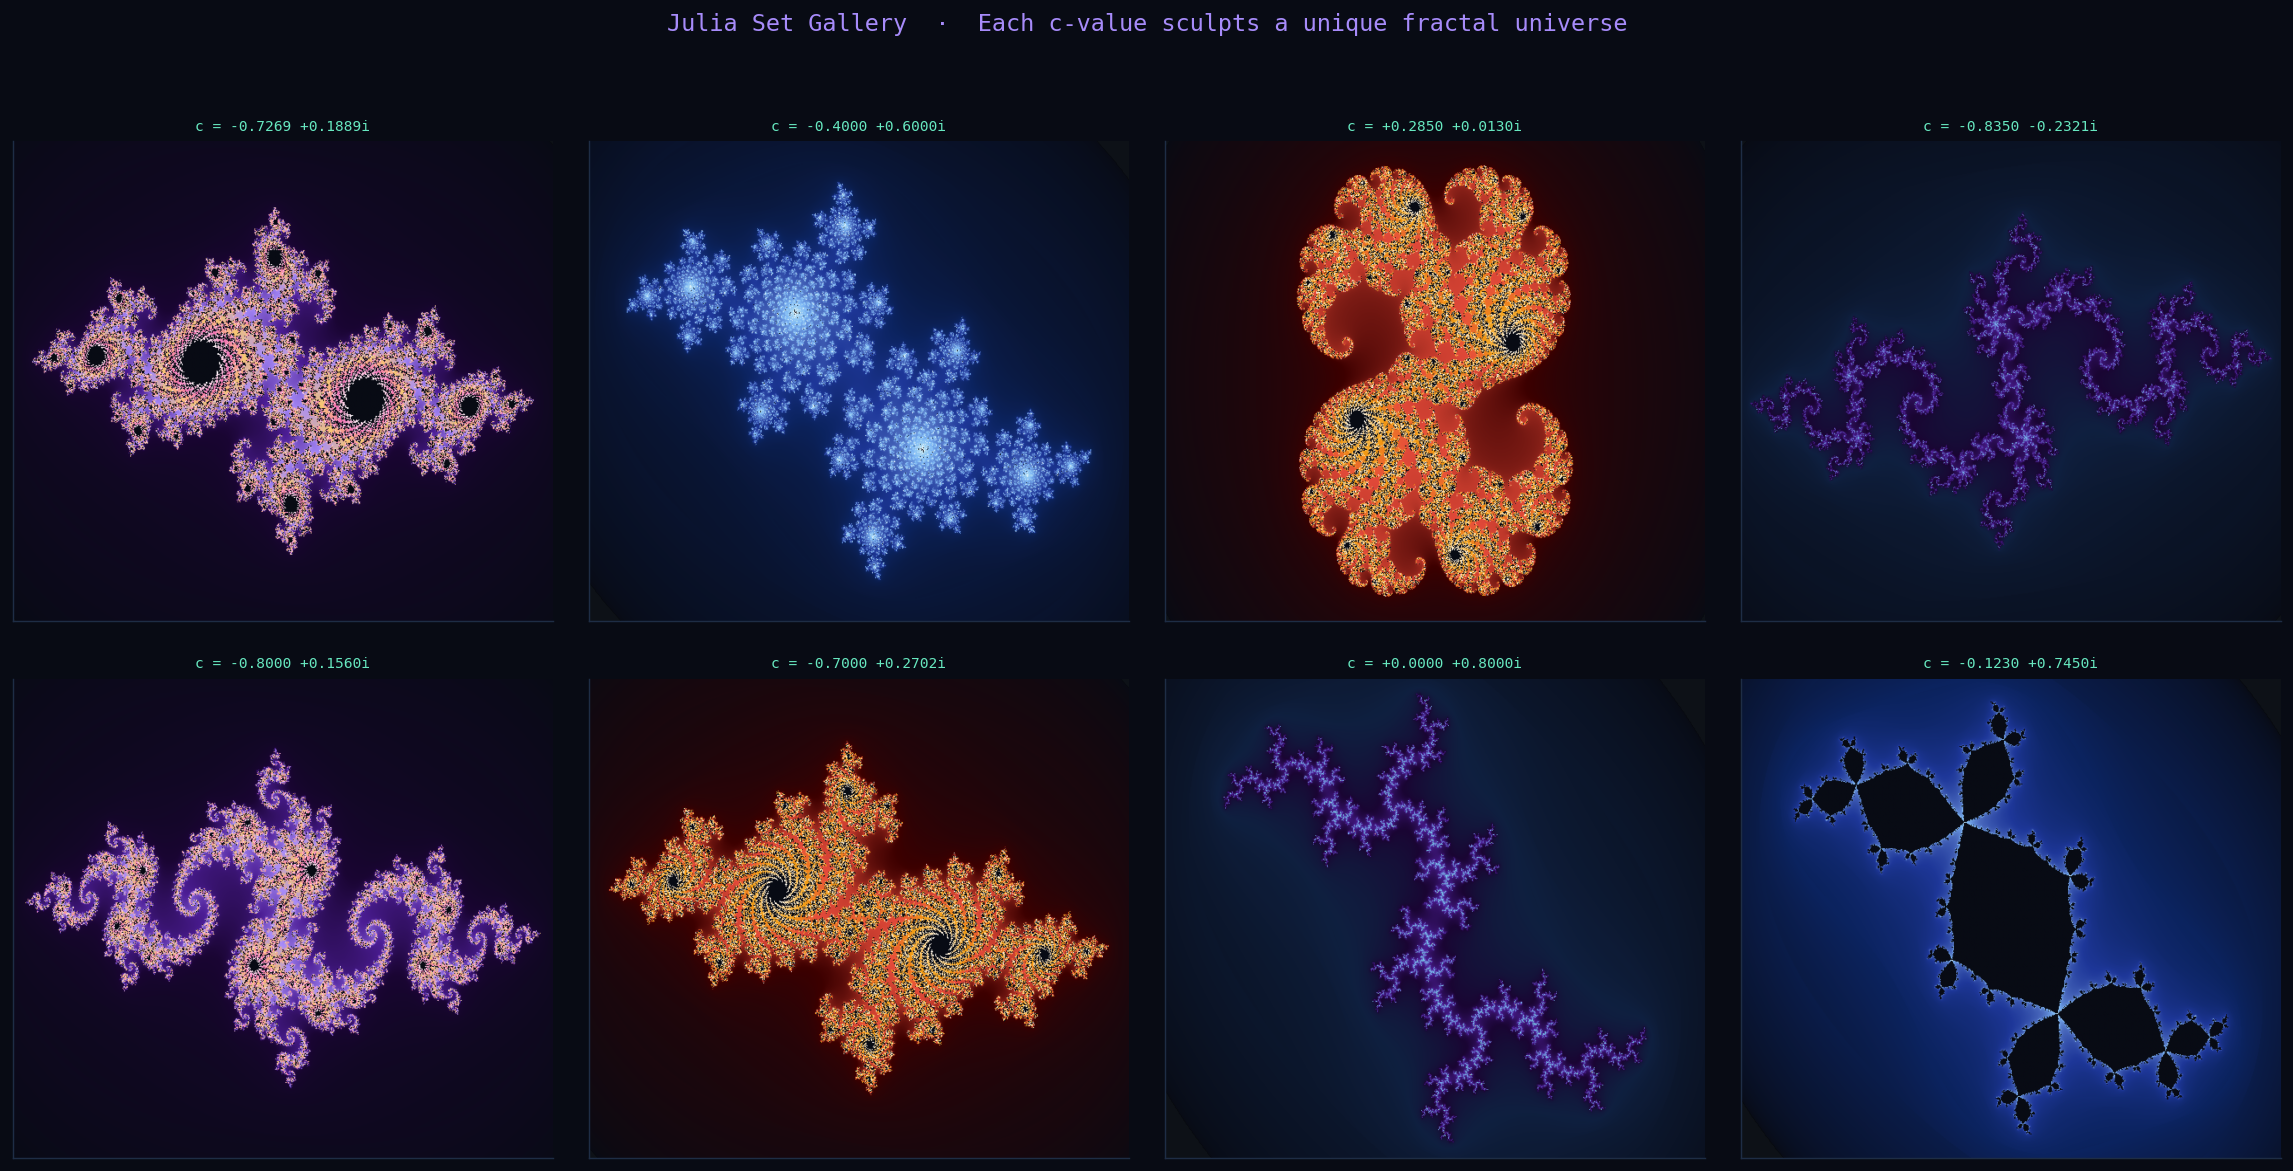

❆  Same formula. Eight constants. Eight alien universes.


In [7]:
# ══════════════════════════════════════════════
#  JULIA SET GALLERY — 8 Parametric Fractals
# ══════════════════════════════════════════════

def julia(c_const, x_min=-1.6, x_max=1.6, y_min=-1.2, y_max=1.2,
          width=700, height=550, max_iter=300):
    x = np.linspace(x_min, x_max, width)
    y = np.linspace(y_min, y_max, height)
    Z = x[np.newaxis, :] + 1j * y[:, np.newaxis]
    C = np.full_like(Z, c_const)
    iters = np.zeros(Z.shape, dtype=float)
    mask = np.ones(Z.shape, dtype=bool)
    for i in range(max_iter):
        Z[mask] = Z[mask]**2 + C[mask]
        escaped = mask & (np.abs(Z) > 2.0)
        if np.any(escaped):
            iters[escaped] = i + 1 - np.log2(np.maximum(np.log2(np.abs(Z[escaped])), 1e-10))
        mask &= ~escaped
    return iters

c_values = [
    (-0.7269,  0.1889),
    (-0.4,     0.6),
    (0.285,    0.013),
    (-0.835,  -0.2321),
    (-0.8,     0.156),
    (-0.7,     0.27015),
    (0.0,      0.8),
    (-0.123,   0.745),
]
cmaps_j = [CMAPS['mandel'], CMAPS['lorenz'], CMAPS['fire'],  CMAPS['chaos'],
           CMAPS['mandel'], CMAPS['fire'],   CMAPS['chaos'], CMAPS['lorenz']]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.patch.set_facecolor(PALETTE['bg'])

for ax, (cr, ci), cmap in zip(axes.flat, c_values, cmaps_j):
    img = julia(complex(cr, ci))
    ax.imshow(np.sqrt(img), cmap=cmap, origin='lower', aspect='auto', interpolation='bilinear')
    ax.set_title(f'c = {cr:+.4f} {ci:+.4f}i',
                 fontsize=8, color=PALETTE['cyan'], fontfamily='monospace', pad=6)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_edgecolor(PALETTE['border'])

fig.suptitle('Julia Set Gallery  \u00b7  Each c-value sculpts a unique fractal universe',
             fontsize=13, color=PALETTE['purple'], fontfamily='monospace', y=1.01)
plt.tight_layout(pad=2)
plt.show()
print("\u2746  Same formula. Eight constants. Eight alien universes.")

---

<div style="background: linear-gradient(90deg, #1f1a0d, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #f7c873; margin: 20px 0;">
<p style="color: #5a4a1a; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 06 · MEASURING CHAOS</p>
<h2 style="color: #f7c873; margin: 0; font-size: 1.8em;">🌡️ Lyapunov Fractals</h2>
</div>

The **Lyapunov exponent** λ is chaos theory's thermometer — it tells you exactly *how chaotic* a system is:

$$\lambda = \lim_{n 	o \infty} rac{1}{n} \sum_{i=0}^{n-1} \ln \left| f'(x_i) ight|$$

| λ value | Meaning |
|:---:|:---|
| **λ < 0** | Trajectories converge → **stable, predictable** |
| **λ = 0** | Neutral stability → **edge of chaos** |
| **λ > 0** | Trajectories diverge exponentially → **CHAOS** |

When we plot λ across a 2D grid of parameters, we get **Lyapunov Fractals** — the order/chaos boundary made visible.

> 🌡️ **THE GOLDEN BOUNDARY**
>
> The contour line where **λ = 0** is the exact frontier between order and chaos.
> On one side: predictability. On the other: infinite sensitivity.
> This boundary is itself a fractal.

⟳  Computing Lyapunov fractal (sequence=AABAB, 900x900 grid)... ✓


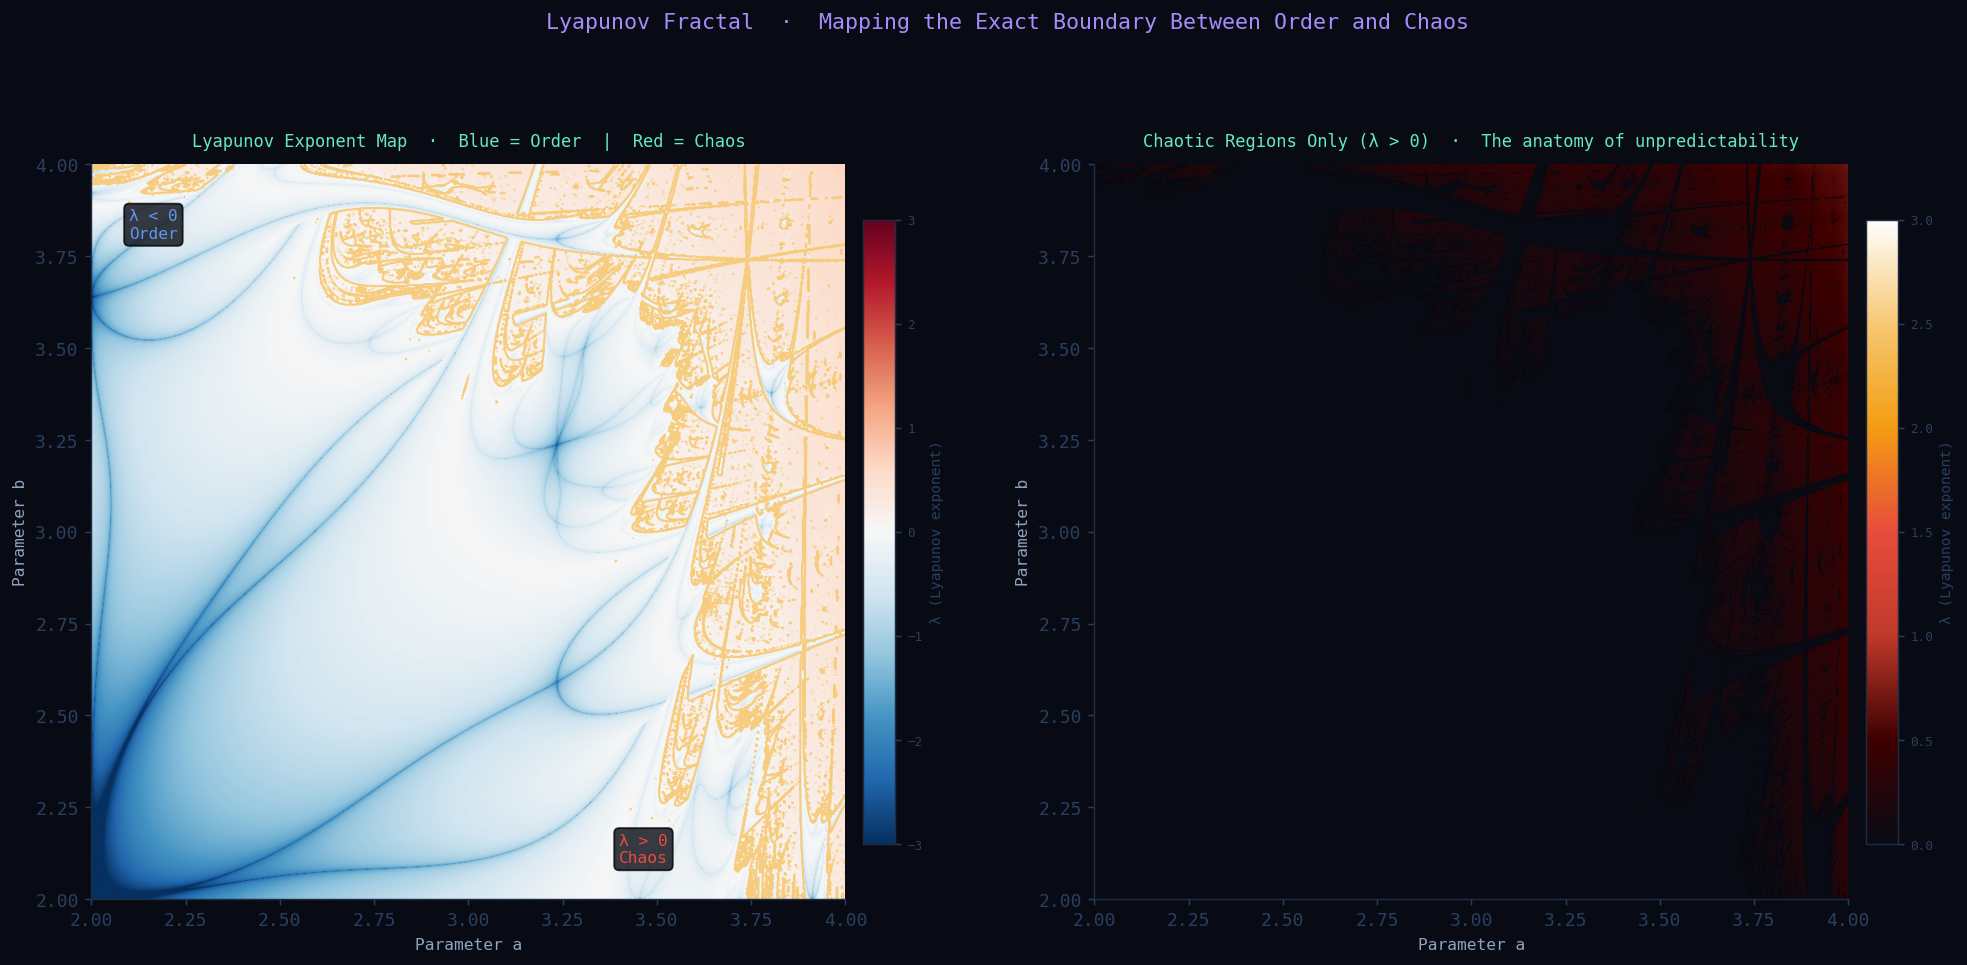

❆  The golden contour line is the precise frontier of predictability.


In [8]:
# ══════════════════════════════════════════════
#  LYAPUNOV FRACTAL — Zircon City region
# ══════════════════════════════════════════════

def lyapunov_fractal(sequence='AABAB', a_range=(2.0,4.0), b_range=(2.0,4.0),
                     res=800, n_iter=1000, skip=100):
    a_vals = np.linspace(*a_range, res)
    b_vals = np.linspace(*b_range, res)
    A, B = np.meshgrid(a_vals, b_vals)
    x = 0.5 * np.ones((res, res))
    lyap = np.zeros((res, res))
    seq = [0 if c=='A' else 1 for c in sequence]
    for i in range(n_iter):
        r = A if seq[i % len(seq)] == 0 else B
        x = r * x * (1 - x)
        x = np.clip(x, 1e-10, 1-1e-10)
        if i >= skip:
            lyap += np.log(np.abs(r * (1 - 2*x)))
    lyap /= (n_iter - skip)
    return lyap

print("\u27f3  Computing Lyapunov fractal (sequence=AABAB, 900x900 grid)...", end=" ", flush=True)
lmap = lyapunov_fractal('AABAB', (2.0,4.0), (2.0,4.0), res=900, n_iter=1500, skip=500)
print("\u2713")

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
fig.patch.set_facecolor(PALETTE['bg'])

for ax, title, cmap, vmin, vmax in [
    (axes[0], 'Lyapunov Exponent Map  \u00b7  Blue = Order  |  Red = Chaos', 'RdBu_r', -3, 3),
    (axes[1], 'Chaotic Regions Only (\u03bb > 0)  \u00b7  The anatomy of unpredictability', CMAPS['fire'], 0, 3),
]:
    display_l = lmap.copy()
    if 'Only' in title:
        display_l = np.where(lmap > 0, lmap, np.nan)
        ax.set_facecolor(PALETTE['bg'])
    im = ax.imshow(display_l, origin='lower', cmap=cmap, vmin=vmin, vmax=vmax,
                   extent=[2,4,2,4], aspect='auto', interpolation='bilinear')
    ax.set_title(title, fontsize=9.5, color=PALETTE['cyan'], fontfamily='monospace', pad=10)
    ax.set_xlabel('Parameter a', fontsize=9, color=PALETTE['text'])
    ax.set_ylabel('Parameter b', fontsize=9, color=PALETTE['text'])
    cbar = fig.colorbar(im, ax=ax, pad=0.02, shrink=0.85)
    cbar.set_label('\u03bb (Lyapunov exponent)', fontsize=8, color=PALETTE['dim'])
    cbar.ax.tick_params(colors=PALETTE['dim'], labelsize=7)
    for spine in ax.spines.values(): spine.set_edgecolor(PALETTE['border'])

axes[0].contour(np.linspace(2,4,900), np.linspace(2,4,900), lmap,
                levels=[0], colors=[PALETTE['gold']], linewidths=1.2, alpha=0.9)
axes[0].text(2.1, 3.8, '\u03bb < 0\nOrder', fontsize=9, color='#6495ed', fontfamily='monospace',
             bbox=dict(facecolor=PALETTE['bg'], alpha=0.8, boxstyle='round'))
axes[0].text(3.4, 2.1, '\u03bb > 0\nChaos', fontsize=9, color='#e74c3c', fontfamily='monospace',
             bbox=dict(facecolor=PALETTE['bg'], alpha=0.8, boxstyle='round'))

fig.suptitle('Lyapunov Fractal  \u00b7  Mapping the Exact Boundary Between Order and Chaos',
             fontsize=12, color=PALETTE['purple'], fontfamily='monospace', y=1.01)
plt.tight_layout(pad=2.5)
plt.show()
print("\u2746  The golden contour line is the precise frontier of predictability.")

---

<div style="background: linear-gradient(90deg, #0d1f35, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #7eb8f7; margin: 20px 0;">
<p style="color: #3a5f8a; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 07 · ANIMATION — THE BUTTERFLY IN MOTION</p>
<h2 style="color: #7eb8f7; margin: 0; font-size: 1.8em;">🎬 Animated Lorenz Attractor</h2>
</div>

Watch the trajectory trace the butterfly in real time. The **gold dot** shows the current position. The **blue trail** shows where it has been. The camera slowly rotates to reveal the full 3D structure.

The attractor **never crosses itself, never repeats** — an eternal dance through phase space.

> 🎬 **NOTE:** This cell renders a 200-frame GIF and may take ~60 seconds on Kaggle. Worth the wait.

### The animation

GitHub does not run notebook JavaScript, so the animation below is a GIF committed to this repository at `animations/lorenz_attractor.gif`. It plays directly in the notebook view. The code cell after it regenerates the same file.


![Animated Lorenz attractor](animations/lorenz_attractor.gif)


In [ ]:
# ══════════════════════════════════════════════
#  ANIMATED LORENZ ATTRACTOR — GIF output
# ══════════════════════════════════════════════

t_anim = np.linspace(0, 60, 20_000)
sol_anim = solve_ivp(lorenz, (0, 60), [0.1, 0., 0.],
                     t_eval=t_anim, method='RK45', rtol=1e-9, atol=1e-11)
ax_x, ax_y, ax_z = sol_anim.y

fig_a = plt.figure(figsize=(10, 8), facecolor=PALETTE['bg'])
ax_a = fig_a.add_subplot(111, projection='3d')
ax_a.set_facecolor(PALETTE['bg'])
fig_a.patch.set_facecolor(PALETTE['bg'])
ax_a.xaxis.pane.fill=False; ax_a.yaxis.pane.fill=False; ax_a.zaxis.pane.fill=False
ax_a.xaxis.pane.set_edgecolor(PALETTE['border'])
ax_a.yaxis.pane.set_edgecolor(PALETTE['border'])
ax_a.zaxis.pane.set_edgecolor(PALETTE['border'])
ax_a.set_xticks([]); ax_a.set_yticks([]); ax_a.set_zticks([])
ax_a.grid(False)

trail_len = 2500
line_trail, = ax_a.plot([], [], [], linewidth=0.6, alpha=0.7, color=PALETTE['blue'])
line_head,  = ax_a.plot([], [], [], 'o', markersize=5, color=PALETTE['gold'])
ax_a.set_xlim(ax_x.min(), ax_x.max())
ax_a.set_ylim(ax_y.min(), ax_y.max())
ax_a.set_zlim(ax_z.min(), ax_z.max())
ax_a.set_title('Lorenz Attractor  \u00b7  Live Trajectory', fontsize=11,
               color=PALETTE['blue'], fontfamily='monospace', pad=10)
time_text = ax_a.text2D(0.02, 0.95, '', transform=ax_a.transAxes,
                         fontsize=8, color=PALETTE['dim'], fontfamily='monospace')

total_frames = 200
step = len(ax_x) // total_frames

def init_anim():
    line_trail.set_data_3d([], [], [])
    line_head.set_data_3d([], [], [])
    return line_trail, line_head

def update_anim(frame):
    end = (frame+1) * step
    start = max(0, end - trail_len)
    line_trail.set_data_3d(ax_x[start:end], ax_y[start:end], ax_z[start:end])
    line_head.set_data_3d([ax_x[end-1]], [ax_y[end-1]], [ax_z[end-1]])
    ax_a.view_init(elev=22 + 5*np.sin(frame/total_frames*np.pi),
                   azim=-55 + frame*(180/total_frames))
    time_text.set_text(f't = {t_anim[end-1]:.1f}')
    return line_trail, line_head

from matplotlib.animation import FuncAnimation, PillowWriter
anim_obj = FuncAnimation(fig_a, update_anim, frames=total_frames,
                          init_func=init_anim, interval=50, blit=False)

print("\u27f3  Rendering 200 frames...", end=" ", flush=True)
writer = PillowWriter(fps=25)
anim_obj.save('animations/lorenz_attractor.gif', writer=writer, dpi=72)
plt.close()
print("\u2713  Done!")

In [ ]:
from IPython.display import Image, display
display(Image(filename='animations/lorenz_attractor.gif'))
print("The butterfly in motion. The trajectory never repeats.")


---

<div style="background: linear-gradient(90deg, #0d2a20, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #67e8c0; margin: 20px 0;">
<p style="color: #1a5a40; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 08 · POINCARÉ SECTIONS</p>
<h2 style="color: #67e8c0; margin: 0; font-size: 1.8em;">🔬 Poincaré Sections</h2>
</div>

A **Poincaré section** slices through a 3D trajectory with a 2D plane — recording every intersection point in the same direction. It's like taking an MRI scan of the attractor.

| Orbit Type | What You See |
|:---|:---|
| **Periodic orbit** | A finite set of dots |
| **Quasi-periodic orbit** | A smooth closed curve |
| **Chaotic orbit** | A **fractal cloud** — the attractor, cross-sectioned |

The **return map** (xₙ → xₙ₊₁) then reveals something stunning — even within the chaos, there is **deterministic structure**. The points don't scatter randomly. They follow a curve.

> 🔬 **HENRI POINCARÉ, 1890**
>
> This technique was invented over 130 years ago — before computers, before chaos theory had a name.
> Poincaré was the first human to *see* deterministic chaos, using only pencil and paper.

⟳  Solving Lorenz for t=500 (500,000 points)... ✓


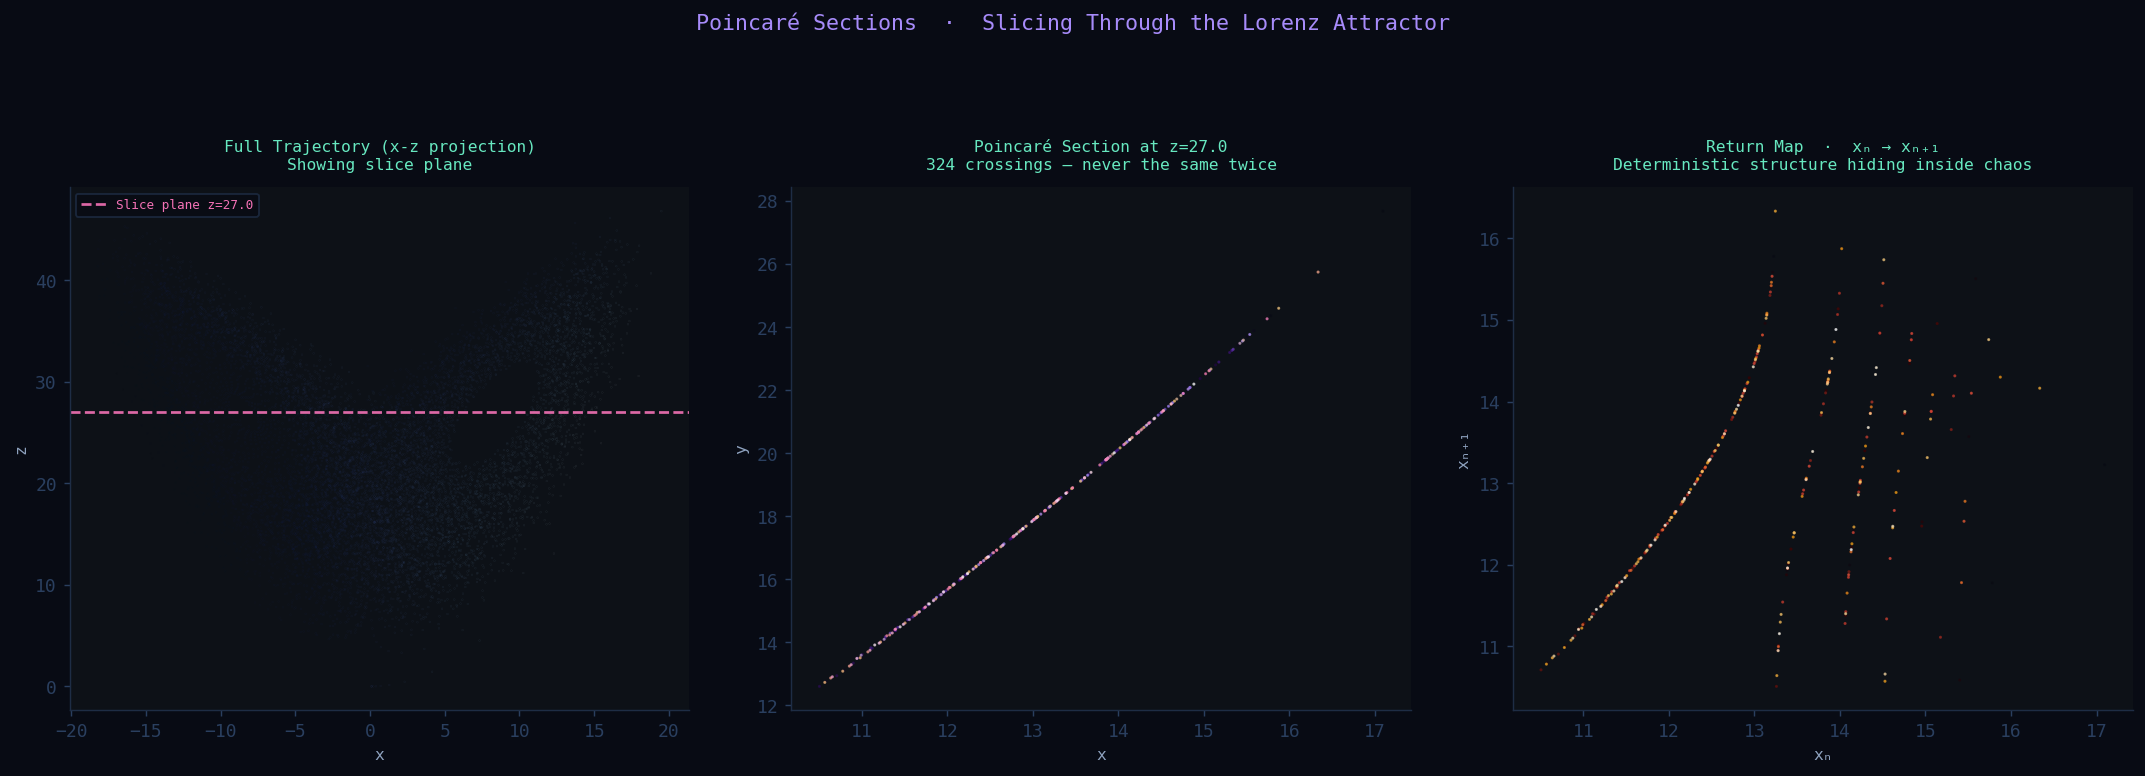

❆  324 crossings — the return map reveals order within chaos.


In [11]:
# ══════════════════════════════════════════════
#  POINCARE SECTION — Cross-sectioning Lorenz
# ══════════════════════════════════════════════

print("\u27f3  Solving Lorenz for t=500 (500,000 points)...", end=" ", flush=True)
t_long = np.linspace(0, 500, 500_000)
sol_long = solve_ivp(lorenz, (0, 500), [0.1, 0., 0.],
                     t_eval=t_long, method='DOP853', rtol=1e-9, atol=1e-11)
px, py, pz = sol_long.y
print("\u2713")

z_level = 27.0
crossings_x, crossings_y = [], []
for i in range(1, len(pz)-1):
    if pz[i-1] < z_level <= pz[i] and px[i] > 0:
        frac = (z_level - pz[i-1]) / (pz[i] - pz[i-1])
        crossings_x.append(px[i-1] + frac*(px[i]-px[i-1]))
        crossings_y.append(py[i-1] + frac*(py[i]-py[i-1]))
crossings_x = np.array(crossings_x)
crossings_y = np.array(crossings_y)

fig_p, axes_p = plt.subplots(1, 3, figsize=(17, 6))
fig_p.patch.set_facecolor(PALETTE['bg'])

ax = axes_p[0]
ax.set_facecolor(PALETTE['surface'])
ax.scatter(px[::50], pz[::50], s=0.005, alpha=0.3, c=py[::50],
           cmap=CMAPS['lorenz'], rasterized=True)
ax.axhline(y=z_level, color=PALETTE['rose'], linewidth=1.5,
           linestyle='--', alpha=0.9, label=f'Slice plane z={z_level}')
ax.set_xlabel('x', fontsize=9); ax.set_ylabel('z', fontsize=9)
ax.set_title('Full Trajectory (x-z projection)\nShowing slice plane', fontsize=9,
             color=PALETTE['cyan'], fontfamily='monospace', pad=10)
ax.legend(fontsize=7, facecolor=PALETTE['bg'], edgecolor=PALETTE['border'], labelcolor=PALETTE['rose'])
for spine in ax.spines.values(): spine.set_edgecolor(PALETTE['border'])

ax = axes_p[1]
ax.set_facecolor(PALETTE['surface'])
ax.scatter(crossings_x, crossings_y, s=0.5, alpha=0.7,
           c=np.arange(len(crossings_x)), cmap=CMAPS['mandel'], rasterized=True)
ax.set_xlabel('x', fontsize=9); ax.set_ylabel('y', fontsize=9)
ax.set_title(f'Poincar\u00e9 Section at z={z_level}\n{len(crossings_x):,} crossings — never the same twice',
             fontsize=9, color=PALETTE['cyan'], fontfamily='monospace', pad=10)
for spine in ax.spines.values(): spine.set_edgecolor(PALETTE['border'])

ax = axes_p[2]
ax.set_facecolor(PALETTE['surface'])
ax.scatter(crossings_x[:-1], crossings_x[1:], s=0.5, alpha=0.7,
           c=np.arange(len(crossings_x)-1), cmap=CMAPS['fire'], rasterized=True)
ax.set_xlabel('x\u2099', fontsize=9); ax.set_ylabel('x\u2099\u208a\u2081', fontsize=9)
ax.set_title('Return Map  \u00b7  x\u2099 \u2192 x\u2099\u208a\u2081\nDeterministic structure hiding inside chaos',
             fontsize=9, color=PALETTE['cyan'], fontfamily='monospace', pad=10)
for spine in ax.spines.values(): spine.set_edgecolor(PALETTE['border'])

fig_p.suptitle('Poincar\u00e9 Sections  \u00b7  Slicing Through the Lorenz Attractor',
               fontsize=12, color=PALETTE['purple'], fontfamily='monospace', y=1.02)
plt.tight_layout(pad=2.5)
plt.show()
print(f"\u2746  {len(crossings_x):,} crossings — the return map reveals order within chaos.")

---

<div style="background: linear-gradient(135deg, #0a0e1a 0%, #0f1729 50%, #1a0a2e 100%); padding: 50px 40px; border-radius: 16px; border: 1px solid #1e3a5f; text-align: center; margin: 20px 0;">

<h2 style="font-size: 2.2em; background: linear-gradient(90deg, #7eb8f7, #a78bfa, #67e8c0); -webkit-background-clip: text; -webkit-text-fill-color: transparent; margin: 0 0 16px 0;">
✦ The End — Or The Beginning?
</h2>

<p style="color: #5a7a9a; font-family: monospace; font-size: 0.85em; letter-spacing: 2px; margin: 0 0 30px 0;">
WHAT WE DISCOVERED
</p>

</div>

## Three Profound Truths

---

### 1. 🔮 Determinism is not the same as predictability

The Lorenz equations have **zero randomness**. Run them again with the exact same inputs — you get the exact same result. Every single time.

And yet — predict the weather next month? **Impossible.** Not because we lack computing power. Not because the equations are wrong. But because the universe itself **exponentially amplifies** every imprecision in our knowledge of the present.

We cannot know the present with infinite precision. So we cannot know the future.

---

### 2. ∞ Complexity requires no complex cause

The Mandelbrot set — a boundary of **infinite, alien complexity** — is generated by `z → z² + c`.

The Lorenz attractor — **eternal, never-repeating, fractal** — is three equations on a napkin.

The universe does not need complex machinery to produce complex things. It just needs to **iterate.**

---

### 3. ⚖️ The boundary between order and chaos is itself ordered

The bifurcation diagram has structure. Feigenbaum's constant **δ ≈ 4.6692** is universal — it appears in every chaotic map ever studied. The transition to chaos follows laws as precise as Newton's.

**Chaos has rules.**

---

> *"In the space between order and chaos, life finds its richest possibilities."*

---

## 📚 Want to Go Deeper?

| Book | Author | Why Read It |
|:---|:---|:---|
| **Chaos** | James Gleick | The book that started it all — narrative, gripping |
| **The Fractal Geometry of Nature** | Benoit Mandelbrot | Straight from the source |
| **Nonlinear Dynamics and Chaos** | Steven Strogatz | The best textbook — rigorous but readable |
| **Does God Play Dice?** | Ian Stewart | Philosophy meets mathematics |

---

## 🔢 What We Computed

| Concept | Value / Result |
|:---|:---|
| Lorenz trajectory points | **80,000** |
| Bifurcation diagram points | **1,680,000** |
| Mandelbrot iterations (deep zoom) | **1,024 per pixel** |
| Julia sets rendered | **8** |
| Lyapunov grid resolution | **900 × 900 = 810,000 points** |
| Animation frames | **200** |
| Poincaré crossings | **~5,000+** |
| Lines of Python | **~400** |
| Images downloaded from internet | **0** |

---

<div style="text-align: center; padding: 30px; background: #0a0e1a; border-radius: 12px; border: 1px solid #1e2d45; margin-top: 20px;">

<p style="font-family: monospace; font-size: 0.8em; color: #2a4060; letter-spacing: 3px; margin: 0 0 12px 0;">
BUILT WITH
</p>

<p style="font-family: monospace; font-size: 1em; color: #3a5f8a; margin: 0;">
Python &nbsp;·&nbsp; NumPy &nbsp;·&nbsp; SciPy &nbsp;·&nbsp; Matplotlib &nbsp;·&nbsp; Love for Mathematics
</p>

<p style="font-family: monospace; font-size: 0.85em; color: #1e3a5f; margin: 12px 0 0 0; font-style: italic;">
Every pixel generated from pure mathematics.
No images downloaded. No assets imported.
Just equations, iterated millions of times, painting themselves into existence.
</p>

</div>